In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv")
print(df.shape)
df.head(5)

(253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

In [3]:
print(df.isnull().sum().sum())
print(df.duplicated().sum().sum())

0
24206


In [4]:
print(df["Diabetes_binary"].value_counts())
print(df["Diabetes_binary"].value_counts(normalize=True))


Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64
Diabetes_binary
0.0    0.860667
1.0    0.139333
Name: proportion, dtype: float64


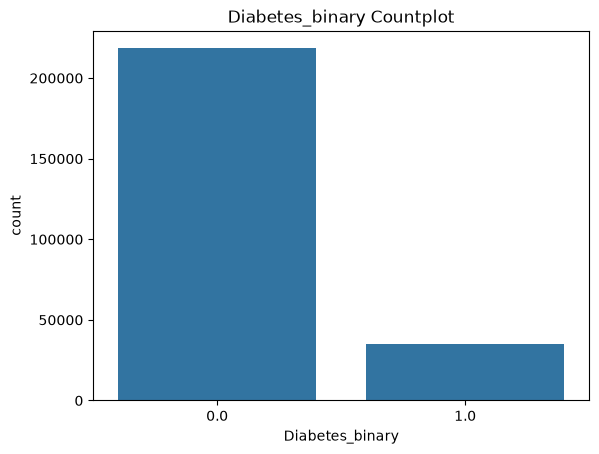

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x="Diabetes_binary", data=df)
plt.title("Diabetes_binary Countplot")
plt.show()

In [6]:
corr = df.corr()["Diabetes_binary"].sort_values(ascending=False)
print(corr)

Diabetes_binary         1.000000
GenHlth                 0.293569
HighBP                  0.263129
DiffWalk                0.218344
BMI                     0.216843
HighChol                0.200276
Age                     0.177442
HeartDiseaseorAttack    0.177282
PhysHlth                0.171337
Stroke                  0.105816
MentHlth                0.069315
CholCheck               0.064761
Smoker                  0.060789
NoDocbcCost             0.031433
Sex                     0.031430
AnyHealthcare           0.016255
Fruits                 -0.040779
Veggies                -0.056584
HvyAlcoholConsump      -0.057056
PhysActivity           -0.118133
Education              -0.124456
Income                 -0.163919
Name: Diabetes_binary, dtype: float64


In [7]:
from sklearn.model_selection import train_test_split
X = df.drop("Diabetes_binary", axis=1)
y = df["Diabetes_binary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,stratify=y, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(202944, 21) (50736, 21) (202944,) (50736,)


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve

lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight='balanced',max_iter=1000, random_state=42))
])
lr.fit(X_train, y_train)
pred =lr.predict(X_test)
print(classification_report(y_test, pred))

proba = lr.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, proba))

              precision    recall  f1-score   support

         0.0       0.95      0.73      0.82     43667
         1.0       0.31      0.76      0.44      7069

    accuracy                           0.73     50736
   macro avg       0.63      0.74      0.63     50736
weighted avg       0.86      0.73      0.77     50736

ROC-AUC: 0.8196313622060201


In [9]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "Logistic Regression": lr,
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20,
        class_weight="balanced", n_jobs=-1, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=42),
}

for name, m in models.items():
    if name != "Logistic Regression":
        m.fit(X_train, y_train)
    proba = m.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print("=====", name)
    print(classification_report(y_test, pred))
    print("ROC-AUC:", roc_auc_score(y_test, proba))

===== Logistic Regression
              precision    recall  f1-score   support

         0.0       0.95      0.73      0.82     43667
         1.0       0.31      0.76      0.44      7069

    accuracy                           0.73     50736
   macro avg       0.63      0.74      0.63     50736
weighted avg       0.86      0.73      0.77     50736

ROC-AUC: 0.8196313622060201
===== Random Forest
              precision    recall  f1-score   support

         0.0       0.95      0.75      0.84     43667
         1.0       0.32      0.75      0.45      7069

    accuracy                           0.75     50736
   macro avg       0.64      0.75      0.64     50736
weighted avg       0.86      0.75      0.78     50736

ROC-AUC: 0.8248881114790414
===== Hist Gradient Boosting
              precision    recall  f1-score   support

         0.0       0.96      0.71      0.81     43667
         1.0       0.30      0.80      0.44      7069

    accuracy                           0.72     507

In [10]:
from sklearn.metrics import precision_recall_curve

best = models["Hist Gradient Boosting"]
proba = best.predict_proba(X_test)[:, 1]

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= t).astype(int)
    print(t)
    print(classification_report(y_test, pred, digits=2))

0.3
              precision    recall  f1-score   support

         0.0       0.98      0.53      0.69     43667
         1.0       0.24      0.92      0.38      7069

    accuracy                           0.58     50736
   macro avg       0.61      0.72      0.53     50736
weighted avg       0.87      0.58      0.64     50736

0.4
              precision    recall  f1-score   support

         0.0       0.97      0.62      0.76     43667
         1.0       0.27      0.87      0.41      7069

    accuracy                           0.65     50736
   macro avg       0.62      0.74      0.58     50736
weighted avg       0.87      0.65      0.71     50736

0.5
              precision    recall  f1-score   support

         0.0       0.96      0.71      0.81     43667
         1.0       0.30      0.80      0.44      7069

    accuracy                           0.72     50736
   macro avg       0.63      0.75      0.63     50736
weighted avg       0.86      0.72      0.76     50736

0.6
   

In [11]:
import xgboost as xgb
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                    scale_pos_weight=ratio, eval_metric="auc",
                    n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)
proba = xgb.predict_proba(X_test)[:, 1]
print(classification_report(y_test, (proba >= 0.5).astype(int)))
print("ROC-AUC:", roc_auc_score(y_test, proba))

              precision    recall  f1-score   support

         0.0       0.95      0.71      0.81     43667
         1.0       0.31      0.79      0.44      7069

    accuracy                           0.72     50736
   macro avg       0.63      0.75      0.63     50736
weighted avg       0.86      0.72      0.76     50736

ROC-AUC: 0.8267092865333464


In [13]:
import joblib
best = models["Hist Gradient Boosting"]
joblib.dump(best, "model.pkl")
joblib.dump(list(X.columns), "columns.pkl")
print("saved")

saved
